# Cavity field test — Python

Generate Gaussian cavity maps from circuit parameters, place them on the solver grid, and visualize the resulting normalized fields.

**Pipeline:** `CavityFieldMap.from_circuit_parameters` → local `z_mm, e_z` → `CavityFields.calculate` → global `ez, C3`.

1. Define the inputs, calculate and plot in this notebook; export `inputs.mat` and `python_results.mat`.
2. Run `cavity_field_test.mlx` in MATLAB for an independent calculation using the same raw inputs.
3. Run `compare_results.ipynb` to compare the saved results.

This test uses **Gaussian maps directly in memory**. It does not save or import text field files. The first case uses standing-wave RF cavities, positive `Qext`, `Nr = 1` and the app's original `N = 200`. No circuit solution, excited RF field, space charge, DC/TWT fields, CST conversion or beam evolution is included.

Running all cells overwrites only this folder's `inputs.mat` and `python_results.mat`; no solver source is changed.


In [4]:
# Import necessary libraries and modules

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from IPython.display import Markdown, display

In [5]:
# Import custom modules and classes to be tested

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "cavity_fields.py").exists()
)
test_directory = project_directory / "test" / "2.cavity_field_test"
sys.path.insert(0, str(project_directory / "src"))

from constants import c, eta0, etom, mu01
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.cavity_field_map import CavityFieldMap
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.cavity_fields import CavityFields

In [6]:
# Set global options for numpy and matplotlib

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.grid": True, "axes.axisbelow": "line",
    "grid.color": "gray", "grid.linestyle": "--",
    "grid.linewidth": 0.7, "grid.alpha": 0.45,
})


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))

## 1. Editable Inputs

Lengths are in mm, frequencies in GHz, beam voltage in kV, current in A, and `RtoQ` in ohms.

The frequencies match the five-cavity example in the [KlyC User Manual](../../../KlyC/Documentation/UserManual.pdf): operating frequency **1000 MHz** on PDF page 3, and cavity frequencies **1000, 1006, 1016, 1030, 1000 MHz** on PDF page 4. The Python inputs below express these same values in **GHz**. `f` is the operating frequency; `f0` contains the individual cavity resonant frequencies.

- `f0, RtoQ, M, s` determine the Gaussian shape and amplitude.
- `N` is the number of **local-map intervals**; `Nz` controls the **solver grid**.
- `zshift` places each cavity on that grid.
- `Pin, Qin, Qext, gaman, Lsb, kai` are not used to solve a circuit here. The app multiplies its generated field by `sign(Qext)`; this first case uses positive values, consistent with the current Python generator.
- `Nr = 1` means one radial field column in the MATLAB Gaussian construction. It is not the number of longitudinal samples.

The MATLAB app normally gets `U0` from its beam-voltage widget. We set that widget's test value to the uniform `Ut[0]`; the solver independently calculates its reference voltage.


In [7]:
# Beam operating point, as in meshgrid_test
Nbeam = 1
rm1 = 0.0
rm2 = 6.0
rc = 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

# Cavity parameters, in cavity-column order
Nc = 5
f = 1.0  # GHz: 1000 MHz, manual example (PDF page 3)
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])  # GHz: [1000, 1006, 1016, 1030, 1000] MHz (page 4)
RtoQ = np.array([182.8959, 116.9999, 102.0570, 123.6318, 180.3864])
M = np.array([0.9225, 0.8930, 0.8192, 0.9518, 0.9325])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{kk + 1}" for kk in range(Nc))
N = 200
Nr = 1

# Same explicit domain as meshgrid_test
z0 = -100.0
L = 3000.0
rcv = np.array([[z0, z0 + L], [1.0, 1.0]])
Nz = 256
Ns = 8
factorregion = 10.0

In [8]:
# Create instances of the parameter classes with the specified values
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=100,
    Ntimes=10, Rlimit=1.0e-4, iterfactor=0.5,
    evolutionmethod=np.array([0.005, 2.0]),
)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

labels = {0: "input", 1: "bunching", -1: "output"}
colors = plt.get_cmap("tab10")(np.arange(Nc) % 10)

show_table(
    ["Column (Python)", "Name", "Type", "nh", "f0 [GHz]", "RtoQ [ohm]", "M", "zshift [mm]"],
    [
        [kk, name, labels[type[kk]], nh[kk], f0[kk], RtoQ[kk], M[kk], zshift[kk]]
        for kk, name in enumerate(cavities.names)
    ],
)
show_table(
    ["Cavity", "Qin", "Qext", "Pin [W]", "gaman", "Lsb [rad]"],
    [[f"C{kk+1}", Qin[kk], Qext[kk], Pin[kk], gaman[kk], f"{Lsb[kk]:.6f}"] for kk in range(Nc)],
)
print("kai =\n", kai)
print(f"Reference: U0={reference.U0:g} kV, I0={reference.I0:g} A, s={reference.s:.6f}")
print(f"Grid: {len(grid.zi)} points, dz={grid.dz:.6f} mm, zi=[{grid.zi[0]:g}, {grid.zi[-1]:g}] mm")

| Column (Python) | Name | Type | nh | f0 [GHz] | RtoQ [ohm] | M | zshift [mm] |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | guide_cavity_1 | input | 1 | 1.0 | 182.8959 | 0.9225 | 0.0 |
| 1 | guide_cavity_2 | bunching | 1 | 1.006 | 116.9999 | 0.893 | 480.0 |
| 2 | guide_cavity_3 | bunching | 1 | 1.016 | 102.057 | 0.8192 | 1630.0 |
| 3 | guide_cavity_4 | bunching | 1 | 1.03 | 123.6318 | 0.9518 | 2400.0 |
| 4 | guide_cavity_5 | output | 1 | 1.0 | 180.3864 | 0.9325 | 2730.0 |

| Cavity | Qin | Qext | Pin [W] | gaman | Lsb [rad] |
| --- | --- | --- | --- | --- | --- |
| C1 | 16428.0 | 334.0 | 60.0 | 0j | 3.141593 |
| C2 | 19768.0 | 95000.0 | 0.0 | 0j | 3.141593 |
| C3 | 19816.0 | 95000.0 | 0.0 | 0j | 3.141593 |
| C4 | 16970.0 | 95000.0 | 0.0 | 0j | 3.141593 |
| C5 | 14787.0 | 50.0 | 0.0 | 0j | 3.141593 |

kai =
 [[0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]]
Reference: U0=180 kV, I0=16 A, s=0.673146
Grid: 3806 points, dz=0.788436 mm, zi=[-100, 2900] mm


## 2. Generate the local Gaussian maps

The local coordinate is centered at the cavity. With `k` and the generator's `k0` in **1/m**:

\[
k=\frac{\omega_0}{2sc\sqrt{-\ln M}},\qquad
e_{zm}=k\sqrt{\frac{R/Q}{\eta_0\pi}\frac{\omega_0}{c}}\,1000^{-3/2},
\]
\[
e_z(z_{\rm mm})=e_{zm}\exp[-(k\,10^{-3}z_{\rm mm})^2].
\]

The local range is \([-3000/k,3000/k]\) mm, with `N+1` samples. Endpoints have amplitude \(e^{-9}\) times the peak. This is **not peak-one normalization**: `e_z` has units mm^(-3/2) and retains the `RtoQ` amplitude.

The exported names `z_mm, e_z` retain all local maps, one column per cavity. In the MATLAB app, the corresponding temporary variables are `z, ez`, reused inside the cavity loop.


| Cavity | Samples | Local minimum [mm] | Local maximum [mm] | Peak e_z [mm^-3/2] |
| --- | --- | --- | --- | --- |
| guide_cavity_1 | 201 | -54.733300 | 54.733300 | 0.0031193275 |
| guide_cavity_2 | 201 | -64.441617 | 64.441617 | 0.0021253767 |
| guide_cavity_3 | 201 | -84.703147 | 84.703147 | 0.0015176769 |
| guide_cavity_4 | 201 | -41.584266 | 41.584266 | 0.0034258259 |
| guide_cavity_5 | 201 | -50.944434 | 50.944434 | 0.0033282487 |

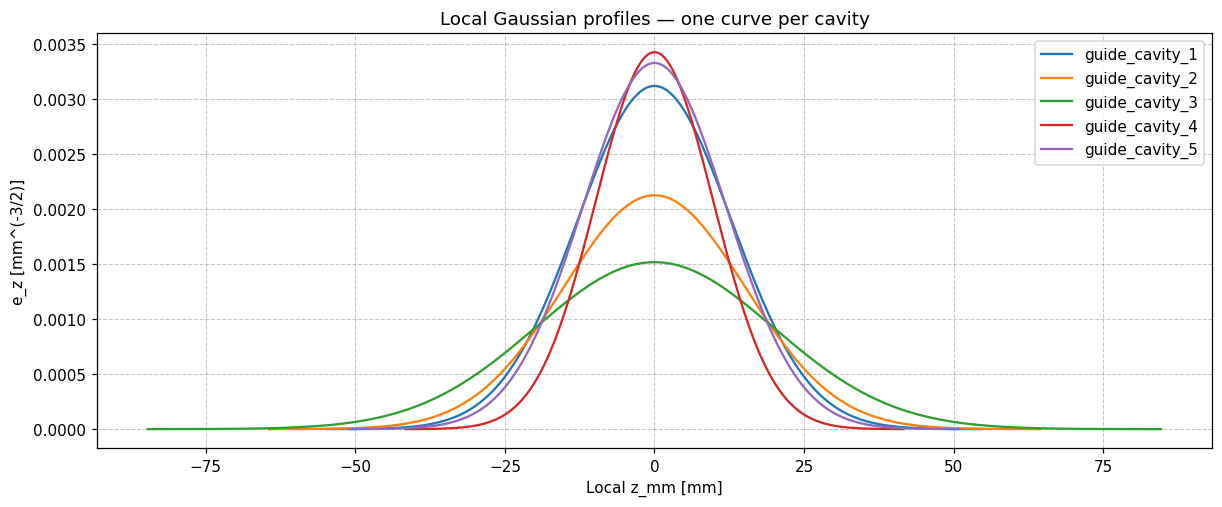

In [9]:
assert Nr == 1 and N == 200
assert np.all(Ut == Ut[0]), "This app comparison uses one uniform beam voltage."
assert np.all((M > 0) & (M < 1)) and np.all(RtoQ > 0)
assert np.all(Qext > 0) and np.all(nh == 1) and np.all(type != 2)

field_maps = CavityFieldMap.from_circuit_parameters(
    cavityname=cavities.names, f0=f0, RtoQ=RtoQ,
    M=M, s=reference.s, N=N,
)
z_mm = np.column_stack([field_maps[name].z_mm for name in cavities.names])
e_z = np.column_stack([field_maps[name].e_z for name in cavities.names])

show_table(
    ["Cavity", "Samples", "Local minimum [mm]", "Local maximum [mm]", "Peak e_z [mm^-3/2]"],
    [[name, len(z_mm), f"{z_mm[0, kk]:.6f}", f"{z_mm[-1, kk]:.6f}",
      f"{np.max(e_z[:, kk]):.8g}"] for kk, name in enumerate(cavities.names)],
)

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for kk, name in enumerate(cavities.names):
    ax.plot(z_mm[:, kk], e_z[:, kk], color=colors[kk], label=name)
ax.set(xlabel="Local z_mm [mm]", ylabel="e_z [mm^(-3/2)]",
       title="Local Gaussian profiles — one curve per cavity")
ax.legend()
plt.show()


## 3. Shift, pad, interpolate, and normalize

`CavityFields.calculate` adds `zshift`, adds two zero samples at each end (`dz/10` and `2*dz/10`), and interpolates linearly on `grid.zi`.

For these RF cavities:
\[
C_3=e_z\frac{\eta_0 I_0}{\sqrt{k_0}\,\beta_e\,U_0\,1000}.
\]

Here **solver** `k0` and `betae` are in **1/mm**, unlike the Gaussian generator's `k0` in 1/m. Both output matrices have one column per cavity. `C3` is dimensionless; neither matrix is the operating RF field obtained after solving for cavity excitation.


ez.shape = (3806, 5) | C3.shape = (3806, 5)


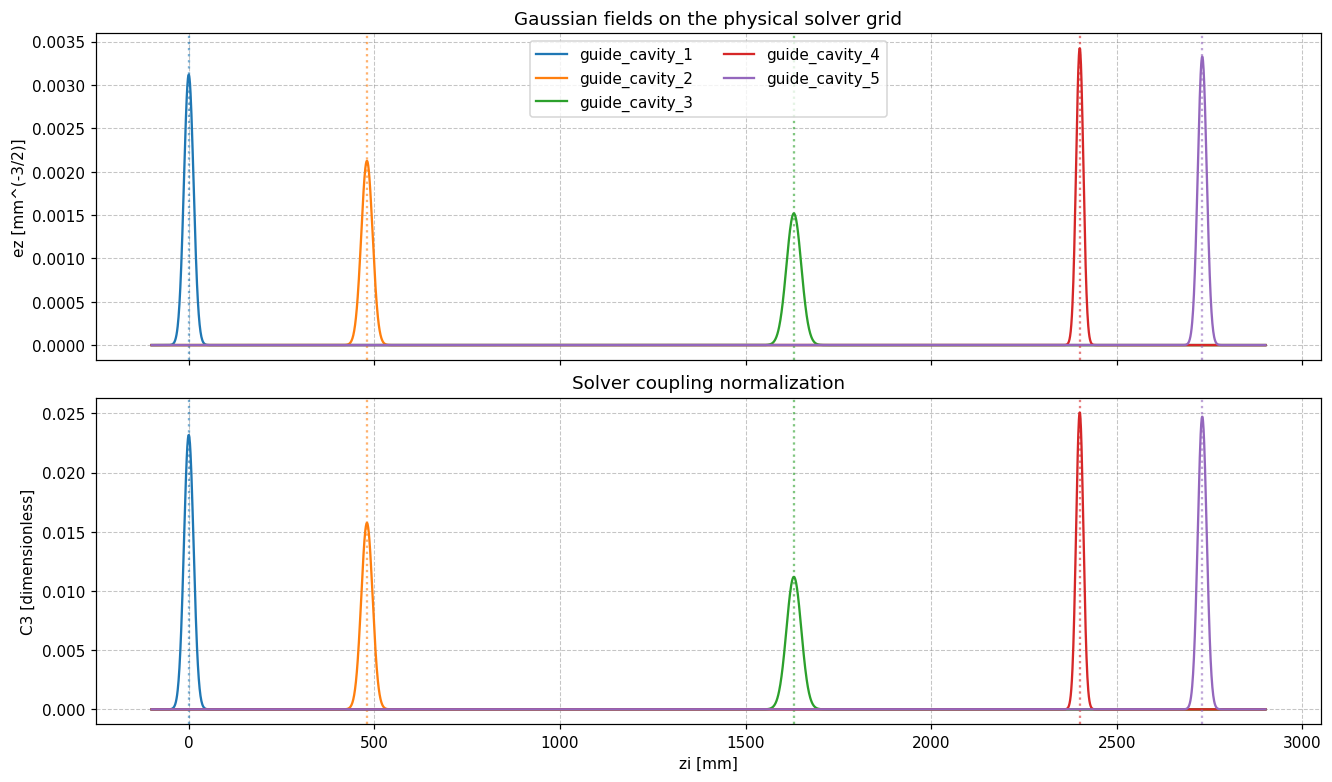

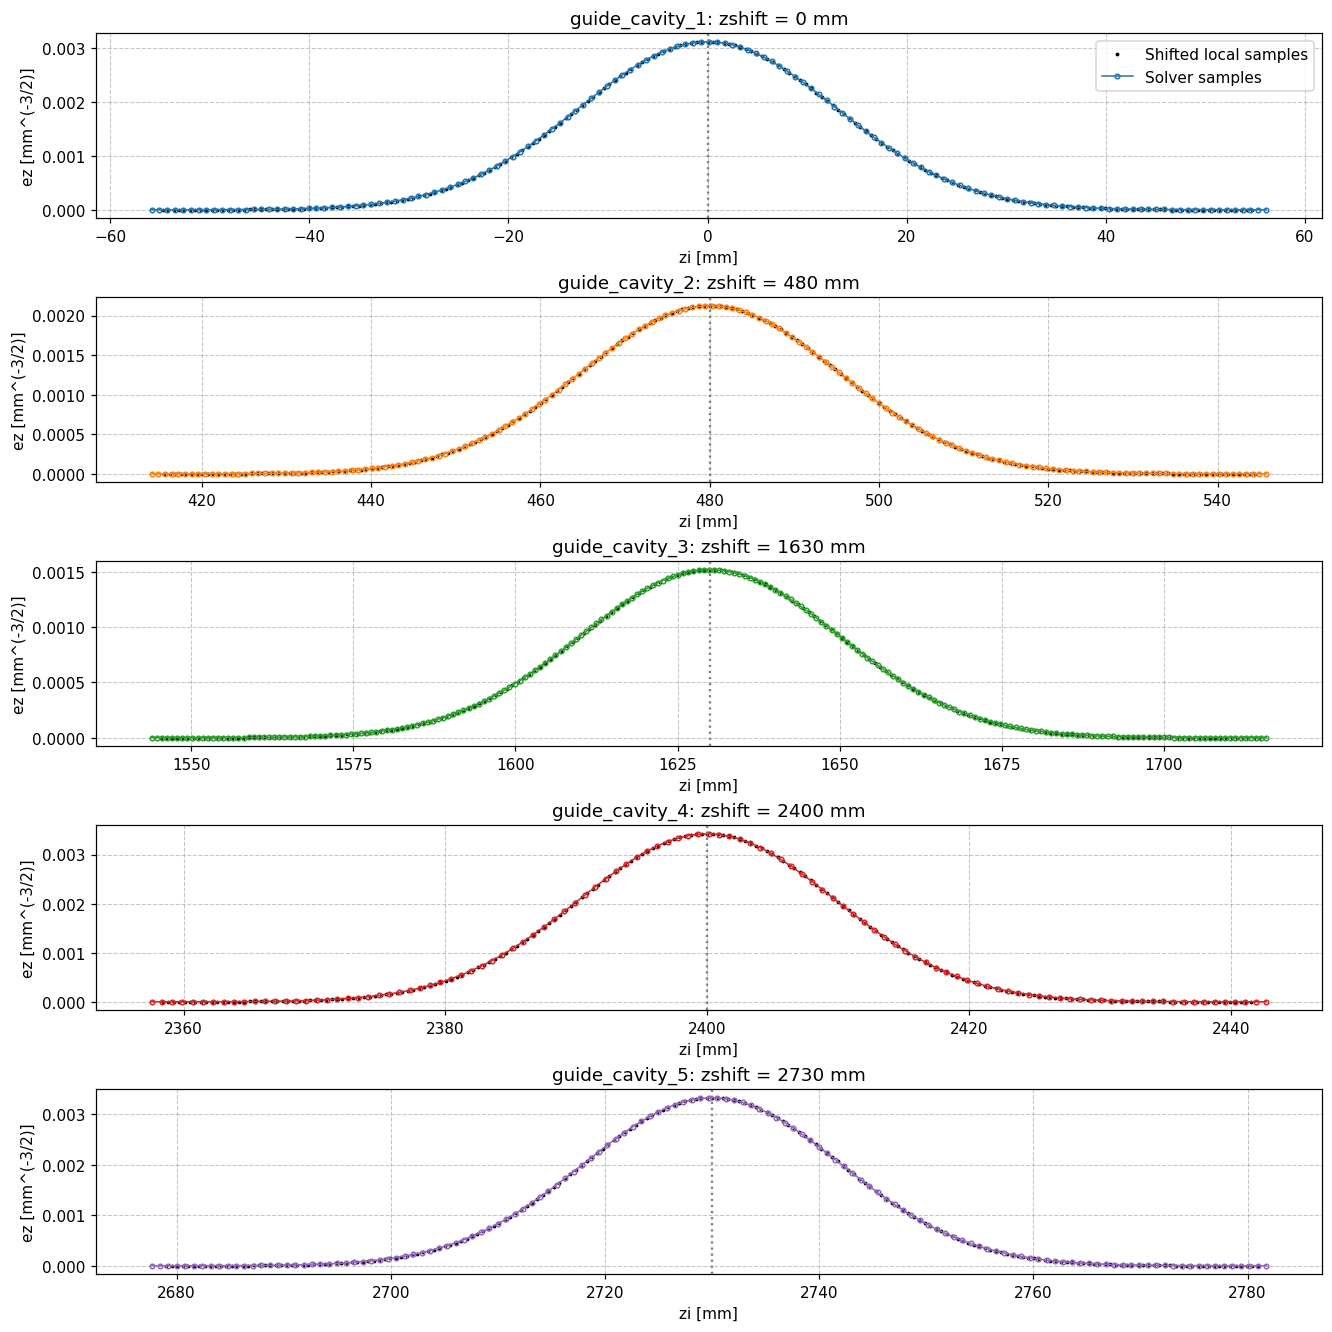

In [10]:
cavity_fields = CavityFields.calculate(
    numerical, cavities, grid, reference, field_maps
)
ez = cavity_fields.ez
C3 = cavity_fields.C3

print("ez.shape =", ez.shape, "| C3.shape =", C3.shape)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
for kk, name in enumerate(cavities.names):
    axes[0].plot(grid.zi, ez[:, kk], color=colors[kk], label=name)
    axes[1].plot(grid.zi, C3[:, kk], color=colors[kk], label=name)
    for ax in axes:
        ax.axvline(zshift[kk], color=colors[kk], linestyle=":", alpha=0.6)
axes[0].set(ylabel="ez [mm^(-3/2)]", title="Gaussian fields on the physical solver grid")
axes[1].set(xlabel="zi [mm]", ylabel="C3 [dimensionless]", title="Solver coupling normalization")
axes[0].legend(ncol=2)
plt.show()

fig, axes = plt.subplots(Nc, 1, figsize=(12, 2.4 * Nc), squeeze=False, layout="constrained")
for kk, name in enumerate(cavities.names):
    ax = axes[kk, 0]
    positions = z_mm[:, kk] + zshift[kk]
    selected = (grid.zi >= positions[0] - 2 * grid.dz) & (grid.zi <= positions[-1] + 2 * grid.dz)
    ax.plot(positions, e_z[:, kk], ".", color="black", markersize=3, label="Shifted local samples")
    ax.plot(grid.zi[selected], ez[selected, kk], "o-", color=colors[kk],
            markersize=3, markerfacecolor="none", linewidth=1, label="Solver samples")
    ax.axvline(zshift[kk], color="gray", linestyle=":")
    ax.set(xlabel="zi [mm]", ylabel="ez [mm^(-3/2)]",
           title=f"{name}: zshift = {zshift[kk]:g} mm")
axes[0, 0].legend()
plt.show()


## 4. First numerical checks

Check dimensions, cavity-column ordering, zero field outside the padded support, interpolation against `np.interp`, and the RF normalization factor.

Recover `RtoQ` and `M` from the local samples and the global grid:
\[
R/Q=\frac{\eta_0}{k_0}\left|\int e_z\,dz_i\right|^2,
\qquad
M=\frac{\left|\int e_z e^{-i(k_0/s)(z_i-z_{shift})}\,dz_i\right|}
{\left|\int e_z\,dz_i\right|}.
\]

Use `zshift = 0` for a local map and **k0 in 1/mm**. These formulas are exact for the infinite Gaussian; finite support, quadrature and interpolation introduce small errors. The local `1e-4` and grid `5e-3` relative tolerances are separate from the tighter Python–MATLAB comparison tolerances.


In [11]:
assert tuple(field_maps) == cavities.names
assert z_mm.shape == (N + 1, Nc)
assert np.all(np.diff(z_mm, axis=0) > 0)
np.testing.assert_allclose(z_mm, -z_mm[::-1], atol=1e-12)
np.testing.assert_allclose(e_z, e_z[::-1], rtol=1e-12, atol=1e-15)
np.testing.assert_allclose(e_z[[0, -1]] / np.max(e_z, axis=0), np.exp(-9), rtol=1e-12)
assert ez.shape == C3.shape == (len(grid.zi), Nc)
assert np.all(np.isfinite(ez)) and np.all(np.isfinite(C3))
np.testing.assert_array_equal(cavity_fields.vpz, np.zeros_like(ez))
np.testing.assert_array_equal(cavity_fields.alfaz, np.zeros_like(ez))

RtoQ_local = np.zeros(Nc)
M_local = np.zeros(Nc)
RtoQ_grid = np.zeros(Nc)
M_grid = np.zeros(Nc)

for kk, name in enumerate(cavities.names):
    positions = z_mm[:, kk] + zshift[kk]
    padding = grid.dz / 10
    AA = np.column_stack((
        np.r_[positions[0] - 2 * padding, positions[0] - padding,
              positions, positions[-1] + padding, positions[-1] + 2 * padding],
        np.r_[0.0, 0.0, e_z[:, kk], 0.0, 0.0],
    ))
    assert AA[0, 0] > grid.zi[0] and AA[-1, 0] < grid.zi[-1]
    expected = np.interp(grid.zi, AA[:, 0], AA[:, 1], left=0, right=0)
    np.testing.assert_allclose(ez[:, kk], expected, rtol=1e-12, atol=1e-15)
    outside = (grid.zi < AA[0, 0]) | (grid.zi > AA[-1, 0])
    np.testing.assert_array_equal(ez[outside, kk], np.zeros(np.sum(outside)))

    expected_C3 = ez[:, kk] * eta0 * reference.I0 / np.sqrt(grid.k0[kk]) / grid.betae / reference.U0 / 1000
    np.testing.assert_allclose(C3[:, kk], expected_C3, rtol=1e-12, atol=1e-15)

    integral = np.trapezoid(e_z[:, kk], x=z_mm[:, kk])
    transit = np.trapezoid(
        e_z[:, kk] * np.exp(-1j * grid.k0[kk] / reference.s * z_mm[:, kk]),
        x=z_mm[:, kk],
    )
    RtoQ_local[kk] = eta0 / grid.k0[kk] * abs(integral)**2
    M_local[kk] = abs(transit) / abs(integral)

    integral = np.trapezoid(ez[:, kk], x=grid.zi)
    transit = np.trapezoid(
        ez[:, kk] * np.exp(-1j * grid.k0[kk] / reference.s * (grid.zi - zshift[kk])),
        x=grid.zi,
    )
    RtoQ_grid[kk] = eta0 / grid.k0[kk] * abs(integral)**2
    M_grid[kk] = abs(transit) / abs(integral)

np.testing.assert_allclose(RtoQ_local, RtoQ, rtol=1e-4, atol=0)
np.testing.assert_allclose(M_local, M, rtol=1e-4, atol=0)
np.testing.assert_allclose(RtoQ_grid, RtoQ, rtol=5e-3, atol=0)
np.testing.assert_allclose(M_grid, M, rtol=5e-3, atol=0)
show_table(
    ["Cavity", "RtoQ input", "RtoQ local", "RtoQ grid", "M input", "M local", "M grid"],
    [[name] + [f"{value[kk]:.7g}" for value in
               (RtoQ, RtoQ_local, RtoQ_grid, M, M_local, M_grid)]
     for kk, name in enumerate(cavities.names)],
)
print("PASS: Gaussian maps, interpolation, zero padding, C3 and normalization-integral checks.")


| Cavity | RtoQ input | RtoQ local | RtoQ grid | M input | M local | M grid |
| --- | --- | --- | --- | --- | --- | --- |
| guide_cavity_1 | 182.8959 | 182.8878 | 182.888 | 0.9225 | 0.9225252 | 0.9225024 |
| guide_cavity_2 | 116.9999 | 116.9947 | 116.9952 | 0.893 | 0.8930313 | 0.8929991 |
| guide_cavity_3 | 102.057 | 102.0525 | 102.0525 | 0.8192 | 0.8192389 | 0.8191895 |
| guide_cavity_4 | 123.6318 | 123.6263 | 123.626 | 0.9518 | 0.9518173 | 0.9518044 |
| guide_cavity_5 | 180.3864 | 180.3784 | 180.3791 | 0.9325 | 0.9325228 | 0.9325009 |

PASS: Gaussian maps, interpolation, zero padding, C3 and normalization-integral checks.


## 5. Export the raw inputs and Python results

`inputs.mat` contains **raw inputs only**, never generated fields or calculated reference/grid quantities. Particle indices `Y0` are exported as one-based MATLAB indices. Integer input parameters are saved as doubles to match MATLAB arithmetic.

`python_results.mat` contains local Gaussian maps, reference/grid quantities used here, final field matrices and integral diagnostics. `cavityname` records the matrix-column order. MATLAB independently regenerates its maps; it never reads Python's calculated results.

Rerun both languages after editing inputs. As in test 1, the result files do not contain an input fingerprint, so their presence alone does not establish that they represent the same case.


In [12]:
inputs = {
    **vars(beam), **vars(cavities), **vars(tube), **vars(numerical),
    "factorregion": factorregion, "RtoQ": RtoQ, "M": M, "N": N, "Nr": Nr,
    "c": c, "etom": etom, "eta0": eta0, "mu01": mu01,
}
inputs["Y0"] = beam.Y0 + 1
for name, value in inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        inputs[name] = np.asarray(value, dtype=float)

python_results = {
    "cavityname": cavityname,
    "z_mm": z_mm, "e_z": e_z,
    "zi": grid.zi, "z": grid.z, "dz": grid.dz, "dt": grid.dt,
    "I0": reference.I0, "U0": reference.U0, "s": reference.s,
    "betae": grid.betae, "k0": grid.k0,
    **vars(cavity_fields),
    "RtoQ_local": RtoQ_local, "M_local": M_local,
    "RtoQ_grid": RtoQ_grid, "M_grid": M_grid,
}
savemat(test_directory / "inputs.mat", inputs, oned_as="row")
savemat(test_directory / "python_results.mat", python_results, oned_as="row")
print("Saved inputs.mat and python_results.mat in", test_directory)
print("Next: run cavity_field_test.mlx in MATLAB, then compare_results.ipynb.")


Saved inputs.mat and python_results.mat in C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\2.cavity_field_test
Next: run cavity_field_test.mlx in MATLAB, then compare_results.ipynb.
